# Ottimizzazione quantistica sul quadrato: QAOA, SAT e Grover

Consideriamo un problema di ottimizzazione combinatoria: dividere i vertici di un grafo in due gruppi in modo che il maggior numero possibile di archi colleghi gruppi diversi. Come possiamo usare un circuito quantistico per favorire gli assegnamenti migliori? E che cosa cambia se, invece di massimizzare il taglio, chiediamo soltanto di superare una soglia?

Seguiremo queste domande sullo stesso esempio, il ciclo di quattro vertici. Costruiremo il costo MaxCut e il circuito QAOA, confronteremo valore atteso e risultati delle misure, quindi esprimeremo la decisione a soglia come SAT. La costruzione dell'oracolo ci permetterà di applicare Grover e di ricondurlo a una particolare famiglia di operatori alternati. Il confronto finale riguarderà il significato dei dati classici prodotti dai due algoritmi.

Il notebook accompagna la dispensa *Ottimizzazione quantistica sul quadrato*. I prerequisiti sono circuiti quantistici, Python e Grover, che assumiamo già noto. Il quadrato è classicamente facile: lo scegliamo perché ogni passaggio può essere calcolato e verificato, senza usarlo come dimostrazione di vantaggio quantistico.

**Scansione della lezione alla lavagna, 150 minuti:** 0–25 motivazione e MaxCut; 25–55 QAOA e valore atteso; 55–80 ampiezze e misure; 80–85 pausa; 85–105 decisione e SAT; 105–125 oracolo reversibile; 125–130 applicazione di Grover; 130–150 operatori alternati e conclusione sulle misure. Le celle sono verifiche da affiancare ai conti o riprendere dopo la lezione, non un ulteriore programma da completare nello stesso tempo.

Il notebook è autonomo: non importa file di questo progetto. Eseguire le celle dall'alto. Se mancano librerie, eseguire una volta in una cella:

```python
%pip install "numpy>=2.1,<3" "scipy>=1.14,<2" "matplotlib>=3.9,<4" "qiskit>=2.2,<3"
```

Gli esercizi invitano a formulare una previsione prima di eseguire il codice. Le soluzioni sono raccolte in fondo. Le verifiche al punto di riferimento usano variabili dedicate, così si possono modificare gli angoli negli esperimenti senza alterare i confronti successivi. L'app collegata ha un'interfaccia in inglese; la dispensa e questo notebook rimangono in italiano. Formule, ordinamento dei bit e valori di riferimento coincidono.

In [1]:
from itertools import product, combinations
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from qiskit.quantum_info import Statevector
SQUARE = ((0, 1), (1, 2), (2, 3), (3, 0))
DIAGONAL = SQUARE + ((0, 2),)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (10, 3.5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})

## 1. Il taglio del quadrato

Sia $G=C_4$ con archi $(1,2),(2,3),(3,4),(4,1)$. Associamo a ogni vertice un bit $x_i$: il suo valore indica a quale gruppo appartiene. Un arco è tagliato precisamente quando i suoi estremi hanno bit diversi. Per questo il suo contributo è l'XOR e il costo totale è

$$C(x)=\sum_{(i,j)\in E}(x_i\oplus x_j).$$

I vertici sono numerati in senso orario. Nel codice gli indici partono da zero, mentre una stringa si legge sempre **x₁x₂x₃x₄ da sinistra a destra**. L'enumerazione seguente è il riferimento classico con cui confronteremo i circuiti.

**Esercizio A.** Quali valori può assumere $C$? Quante stringhe ottime ci aspettiamo? Confrontare 0011, 0101 e 1010, distinguendo un assegnamento dalla bipartizione non ordinata che rappresenta.

In [2]:
def assignments(n=4):
    return np.array(list(product((0, 1), repeat=n)), dtype=int)

def labels(n=4):
    return [format(i, f"0{n}b") for i in range(2**n)]

def costs(edges=SQUARE, n=4):
    bits = assignments(n)
    return sum((bits[:, i] ^ bits[:, j] for i, j in edges), np.zeros(2**n, dtype=int))

In [3]:
c = costs()
for x, value in zip(labels(), c):
    print(x, '→', value)
print('Spettro e molteplicità:', np.unique(c, return_counts=True))
print('Ottimi:', np.array(labels())[c == c.max()])
assert list(np.array(labels())[c == 4]) == ['0101', '1010']

0000 → 0
0001 → 2
0010 → 2
0011 → 2
0100 → 2
0101 → 4
0110 → 2
0111 → 2
1000 → 2
1001 → 2
1010 → 4
1011 → 2
1100 → 2
1101 → 2
1110 → 2
1111 → 0
Spettro e molteplicità: (array([0, 2, 4]), array([ 2, 12,  2]))
Ottimi: ['0101' '1010']


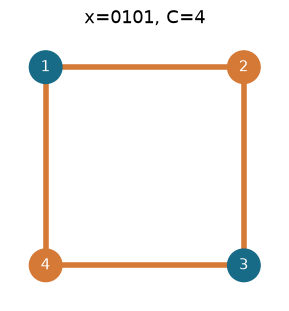

In [4]:
x = np.array([0, 1, 0, 1])  # modifica questo assegnamento
pos = np.array([[0,1], [1,1], [1,0], [0,0]])
fig, ax = plt.subplots(figsize=(4, 3.5))
for i,j in SQUARE:
    ax.plot(pos[[i,j],0], pos[[i,j],1], lw=4,
            color='#D57936' if x[i] != x[j] else '#A9B7BE')
ax.scatter(pos[:,0],pos[:,1],s=550,c=['#176B87' if b==0 else '#D57936' for b in x],zorder=3)
for i,(px,py) in enumerate(pos):ax.text(px,py,f'{i+1}',color='white',ha='center',va='center')
ax.set_title(f'x={"".join(map(str,x))}, C={sum(x[i]^x[j] for i,j in SQUARE)}')
ax.set(xlim=(-.18,1.18),ylim=(-.18,1.18))
ax.set_aspect('equal'); ax.axis('off'); plt.show()

## 2. QAOA e valore atteso del costo

Il Quantum Approximate Optimization Algorithm costruisce una famiglia di stati parametrizzati e cerca classicamente i parametri che migliorano il costo medio. Per collegare il circuito al problema occorre anzitutto rappresentare $C$ come osservabile. Il bit diventa il proiettore $\widehat x_i=(I-Z_i)/2$; sostituendo nell'identità $x_i\oplus x_j=x_i+x_j-2x_ix_j$ si ottiene

$$H_C=\sum_{(i,j)\in E}\frac{I-Z_iZ_j}{2},\qquad H_M=\sum_i X_i.$$
$$|\psi_1\rangle=e^{-i\beta H_M}e^{-i\gamma H_C}|+\rangle^{\otimes4}.$$

Qui $H_C|x\rangle=C(x)|x\rangle$, mentre $H_M$ è una scelta distinta: connette stringhe che differiscono in un bit. Il costo imprime fasi $e^{-i\gamma C(x)}$ senza cambiare le probabilità; il mixer permette a contributi provenienti da stringhe diverse di interferire. Applicato da solo alla sovrapposizione uniforme, anche il mixer produce soltanto una fase globale. È la loro alternanza a rendere possibile una distribuzione dipendente dal costo.

Con $p$ strati applichiamo, in ordine temporale, costo e mixer per ciascuno strato. Massimizziamo
$$F_{G,p}(\boldsymbol\beta,\boldsymbol\gamma)=\sum_x|\langle x|\psi_p\rangle|^2C_G(x).$$
Una buona media e un'alta probabilità di ottenere l'ottimo sono quantità diverse. La famiglia con $p+1$ strati contiene quella con $p$ strati, ma un ottimizzatore locale non è per questo garantito a trovare un risultato migliore.

Il simulatore usa le sedici ampiezze dello stato. Questa scelta rende trasparenti le verifiche sul piccolo esempio; memorizzare uno stato generico di $n$ qubit richiederebbe $2^n$ ampiezze.

In [5]:
def uniform(n=4):
    return np.full(2**n, 1 / np.sqrt(2**n), dtype=complex)

def x_mixer(state, beta):
    """Applica exp(-i beta sum_j X_j) senza costruire una matrice densa."""
    state = np.asarray(state, dtype=complex).copy()
    n = int(np.log2(len(state)))
    indices = np.arange(len(state))
    for j in range(n):
        state = np.cos(beta) * state - 1j * np.sin(beta) * state[indices ^ (1 << j)]
    return state

def projector_mixer(state, beta):
    """exp(-i beta |s><s|)."""
    return state + (np.exp(-1j * beta) - 1) * np.mean(state)

def alternating(diagonal, betas, gammas, mixer="x"):
    if len(betas) != len(gammas):
        raise ValueError("Each layer requires one beta and one gamma.")
    if mixer not in ("x", "projector"):
        raise ValueError("Unknown mixer.")
    state = uniform(int(np.log2(len(diagonal))))
    mix = x_mixer if mixer == "x" else projector_mixer
    for beta, gamma in zip(betas, gammas):
        state *= np.exp(-1j * gamma * np.asarray(diagonal))
        state = mix(state, beta)
    return state

def qaoa(betas, gammas, edges=SQUARE):
    return alternating(costs(edges), betas, gammas)

def expectation(state, diagonal):
    return float(np.dot(np.abs(state)**2, diagonal))

In [6]:
beta, gamma = np.pi/8, np.pi/4  # angoli modificabili per l'esperimento
after_cost = np.exp(-1j*gamma*c)*uniform()
state = qaoa([beta], [gamma])
print('Probabilità dopo il solo costo:', np.abs(after_cost)**2)
print('Taglio medio:', expectation(state,c))
print('Probabilità ottimo:', np.sum(np.abs(state[c==4])**2))
assert np.allclose(np.abs(after_cost)**2, 1/16)
reference_state = qaoa([np.pi/8], [np.pi/4])
assert np.isclose(expectation(reference_state,c), 3)
assert np.isclose(np.sum(np.abs(reference_state[c==4])**2), 17/32)

Probabilità dopo il solo costo: [0.0625 0.0625 0.0625 0.0625 0.0625 0.0625 0.0625 0.0625 0.0625 0.0625
 0.0625 0.0625 0.0625 0.0625 0.0625 0.0625]
Taglio medio: 3.0
Probabilità ottimo: 0.53125


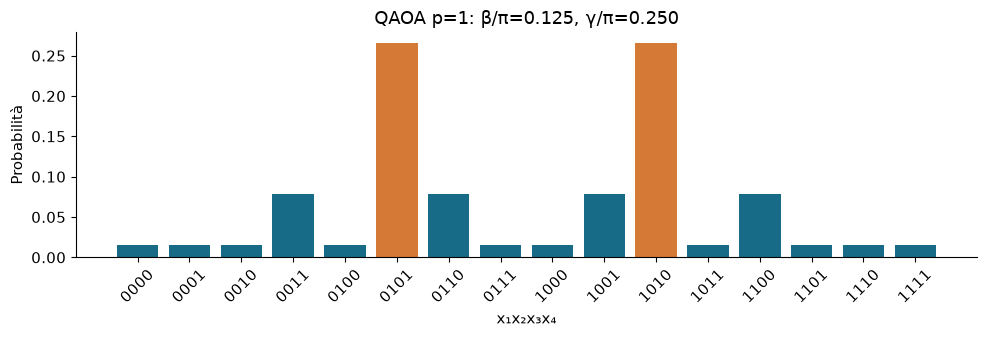

In [7]:
def plot_probabilities(psi, title, counts=None):
    fig, ax = plt.subplots()
    ax.bar(labels(), np.abs(psi)**2, color=['#D57936' if v==4 else '#176B87' for v in c])
    if counts is not None:ax.plot(labels(),counts/counts.sum(),'kd',label='Frequenze campionate')
    ax.set(xlabel='x₁x₂x₃x₄', ylabel='Probabilità', title=title)
    ax.tick_params(axis='x',rotation=45)
    if counts is not None:ax.legend()
    fig.tight_layout(); plt.show()
plot_probabilities(state,f'QAOA p=1: β/π={beta/np.pi:.3f}, γ/π={gamma/np.pi:.3f}')

**Esercizio B.** Impostare prima β=0 e variare γ, poi γ=0 e variare β. Spiegare la distribuzione ottenuta usando l'azione dei due operatori.

### Il calcolo di $F_1$

Per simmetria i quattro archi hanno lo stesso valore atteso, dunque $F_1=2-2\langle Z_1Z_2\rangle$. Nella rappresentazione di Heisenberg facciamo evolvere l'osservabile, prima con il mixer e poi con il costo:
$$U_M^\dagger Z_1Z_2U_M=c_\beta^2Z_1Z_2+c_\beta s_\beta(Z_1Y_2+Y_1Z_2)+s_\beta^2Y_1Y_2,$$
dove $c_\beta=\cos(2\beta)$ e $s_\beta=\sin(2\beta)$. Dopo la coniugazione con $U_C$, soltanto le stringhe di Pauli composte da $I$ e $X$ hanno media non nulla in $|s\rangle$. I termini misti contribuiscono ciascuno $-\sin\gamma\cos\gamma$, mentre i termini $ZZ$ e $YY$ hanno media nulla. Ne segue
$$\langle Z_1Z_2\rangle=-\tfrac12\sin(4\beta)\sin(2\gamma),$$
e quindi
$$F_1(\beta,\gamma)=2+\sin(4\beta)\sin(2\gamma).$$
La sezione 4 della dispensa svolge tutte le coniugazioni. Il limite $F_1\leq3$ è raggiunto da $\beta=\pi/8$, $\gamma=\pi/4$ e dimostra il massimo globale a uno strato. Il taglio ottimo classico vale invece 4; una singola misura può avere costo 0, 2 o 4, mai 3. In questo caso possiamo scegliere gli angoli analiticamente, senza un ciclo di ottimizzazione mediante misure.

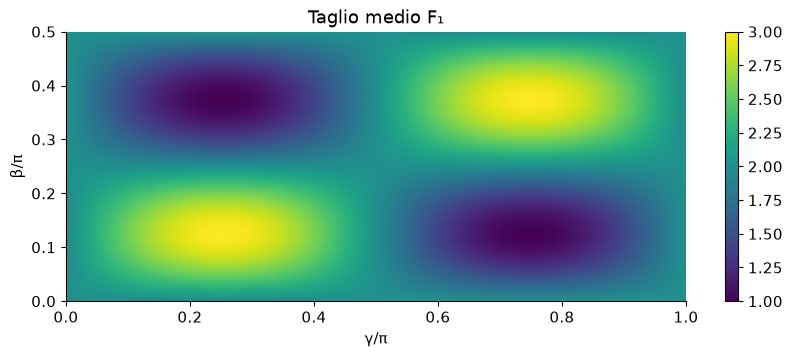

In [8]:
betas=np.linspace(0,np.pi/2,101)
gammas=np.linspace(0,np.pi,101)
landscape=2+np.sin(4*betas[:,None])*np.sin(2*gammas[None,:])
fig,ax=plt.subplots()
im=ax.imshow(landscape,origin='lower',extent=[0,1,0,.5],aspect='auto',cmap='viridis')
ax.set(xlabel='γ/π',ylabel='β/π',title='Taglio medio F₁')
fig.colorbar(im,ax=ax);plt.show()
for b,g in [(0.2,0.7),(-0.3,1.2),(np.pi/8,np.pi/4)]:
    assert np.isclose(expectation(qaoa([b],[g]),c),2+np.sin(4*b)*np.sin(2*g))

### Dalle ampiezze alla distribuzione di misura

Per calcolare lo stato completo possiamo sfruttare il prodotto tensoriale del mixer. Se $d(x,z)$ è il numero di bit in cui le due stringhe differiscono, allora
$$\langle z|\psi_1\rangle=\frac14\sum_x e^{-i\gamma C(x)}(\cos\beta)^{4-d(x,z)}(-i\sin\beta)^{d(x,z)}.$$
Le simmetrie del quadrato e il complemento di tutti i bit raccolgono le sedici stringhe in quattro classi. Al punto di riferimento $\beta=\pi/8$, $\gamma=\pi/4$ troviamo:

| Rappresentante | Numero di stringhe | Costo | Ampiezza per stringa | Probabilità per stringa |
|---|---:|---:|---|---|
| 0000 | 2 | 0 | $i/8$ | $1/64$ |
| 0001 | 8 | 2 | $-1/8$ | $1/64$ |
| 0011 | 4 | 2 | $-1/4-i/8$ | $5/64$ |
| 0101 | 2 | 4 | $-1/2+i/8$ | $17/64$ |

La sezione 5 della dispensa deriva ciascuna ampiezza. Qui verifichiamo la somma tramite le distanze di Hamming e controlliamo normalizzazione, media e successo. Le due classi di costo 2 hanno probabilità diverse: il mixer conserva informazione sulla struttura delle stringhe, oltre al loro costo.

In [9]:
bits = assignments()
distance = np.sum(bits[:,None,:] != bits[None,:,:], axis=2)
mixer_entries = np.cos(np.pi/8)**(4-distance) * (-1j*np.sin(np.pi/8))**distance
from_hamming = mixer_entries @ (np.exp(-1j*np.pi*c/4)/4)
expected_amplitudes = np.full(16,-1/8,dtype=complex)
expected_amplitudes[[0,15]] = 1j/8
expected_amplitudes[[3,6,9,12]] = -1/4-1j/8
expected_amplitudes[[5,10]] = -1/2+1j/8
assert np.allclose(from_hamming,reference_state)
assert np.allclose(reference_state,expected_amplitudes)
for value in (0,2,4):
    print(f'P(C={value}) = {np.sum(np.abs(reference_state[c==value])**2):.6f}')
print('Normalizzazione:',np.sum(np.abs(reference_state)**2))

P(C=0) = 0.031250
P(C=2) = 0.437500
P(C=4) = 0.531250
Normalizzazione: 1.0


Raggruppando per costo otteniamo $P_0=1/32$, $P_2=7/16$, $P_4=17/32$, da cui $F_1=3$. Il rapporto $F_1/C_{\max}=3/4$ confronta il costo medio QAOA con l'ottimo classico, mentre $17/32$ è la probabilità di misurare un ottimo.

Più in generale $F=2+2(P_4-P_0)$: una media di 3 impone $P_4-P_0=1/2$, senza fissare separatamente le due probabilità. La distribuzione appena calcolata è quella dello specifico circuito al punto di riferimento.

### Verifica con porte Qiskit

$R_{ZZ}(\theta)=e^{-i\theta ZZ/2}$: usiamo **RZZ(−γ)** per ogni arco e **RX(2β)** per ogni qubit. La fase globale del costo è inclusa. Mappiamo x₁ su q₃: l'ordine di stampa Qiskit q₃q₂q₁q₀ coincide così con x₁x₂x₃x₄.

In [10]:
def qiskit_qaoa(betas, gammas, edges=SQUARE, n=4):
    from qiskit import QuantumCircuit
    qc = QuantumCircuit(n)
    qc.h(range(n))
    for beta, gamma in zip(betas, gammas):
        # Conserva la fase costante per confrontare direttamente le ampiezze.
        qc.global_phase -= gamma * len(edges) / 2
        for i, j in edges:
            qc.rzz(-gamma, n-1-i, n-1-j)
        qc.rx(2*beta, range(n))
    return qc

In [11]:
circuit=qiskit_qaoa([beta],[gamma])
print(circuit.draw(output='text'))
qiskit_state=Statevector.from_instruction(circuit).data
assert np.allclose(qiskit_state,state)
print('NumPy e circuito Qiskit coincidono, incluse le fasi.')

global phase: 3π/2
     ┌───┐                                            ┌─────────┐
q_0: ┤ H ├───────────────────────■──────────■─────────┤ Rx(π/4) ├
     ├───┤                       │ZZ(-π/4)  │         ├─────────┤
q_1: ┤ H ├────────────■──────────■──────────┼─────────┤ Rx(π/4) ├
     ├───┤            │ZZ(-π/4) ┌─────────┐ │         └─────────┘
q_2: ┤ H ├─■──────────■─────────┤ Rx(π/4) ├─┼────────────────────
     ├───┤ │ZZ(-π/4)            └─────────┘ │ZZ(-π/4) ┌─────────┐
q_3: ┤ H ├─■────────────────────────────────■─────────┤ Rx(π/4) ├
     └───┘                                            └─────────┘
NumPy e circuito Qiskit coincidono, incluse le fasi.


### Misure ripetute e ottimizzazione classica

Una misura restituisce una stringa $x$. Ripetendo la preparazione e la misura $S$ volte raccogliamo una sequenza di risultati classici, detta anche *transcript*. Ogni ripetizione è uno *shot*. Per stimare un osservabile diagonale bastano i conteggi $n_x$ delle stringhe. Una sola stringa permette di valutare tutti gli archi, perché i termini di costo sono diagonali nella stessa base.

$$\widehat F=\frac{1}{S}\sum_x n_x C(x).$$

Il campionamento è ideale: descrive la statistica di un numero finito di misure, senza rumore hardware. La varianza dello stimatore è $\operatorname{Var}(C)/S$; al punto di riferimento $\operatorname{Var}(C)=5/4$. Calcoliamo comunque la varianza dallo stato corrente, così il confronto rimane valido anche cambiando gli angoli.

**Esercizio C.** Variare il numero di misure e il seme del generatore casuale. Perché `int(stringa, 2)` non è il costo MaxCut? Un singolo campione deve necessariamente avvicinarsi alla media esatta quando aumentiamo il numero di misure?

In [12]:
def sample(state, shots=1024, seed=7):
    p = np.abs(state)**2
    return np.random.default_rng(seed).multinomial(shots, p / p.sum())

Media campionata: 2.9296875
Media esatta: 3.0
Errore standard teorico: 0.034938562148434216


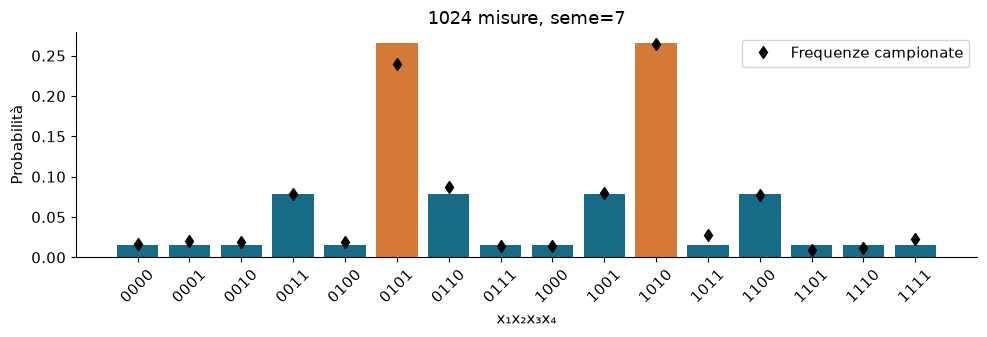

In [13]:
shots, seed = 1024, 7
counts=sample(state,shots,seed)
print('Media campionata:',counts@c/shots)
print('Media esatta:',expectation(state,c))
variance = expectation(state,(c-expectation(state,c))**2)
print('Errore standard teorico:',np.sqrt(variance/shots))
plot_probabilities(state,f'{shots} misure, seme={seed}',counts)

L'ottimizzatore seguente usa il valore atteso **esatto** del simulatore. È un confronto con il massimo analitico, non un'ottimizzazione alimentata da misure finite. Su un dispositivo, ogni valutazione del costo verrebbe invece stimata da un nuovo insieme di misure e l'ottimizzatore dovrebbe gestirne l'incertezza. Le curve mostrano tutte le valutazioni della funzione, comprese quelle usate per stimare numericamente il gradiente; non devono essere monotone.

In [14]:
def optimize_qaoa(p=1, edges=SQUARE, seed=7, starts=4):
    """Ottimizza la media esatta; le valutazioni non usano shots finiti."""
    from scipy.optimize import minimize
    rng = np.random.default_rng(seed)
    c = costs(edges)
    best = None
    histories = []
    for start in range(starts):
        history = []
        x0 = rng.uniform(0, np.pi, 2*p)
        def objective(theta):
            value = expectation(qaoa(theta[:p], theta[p:], edges), c)
            history.append(value)
            return -value
        result = minimize(objective, x0, method="BFGS", options={"maxiter":200, "gtol":1e-8})
        histories.append(history)
        if best is None or result.fun < best.fun:
            best = result
    return best, histories

Angoli β: [1.1781] angoli γ: [2.35619]
Miglior valore trovato: 3.0


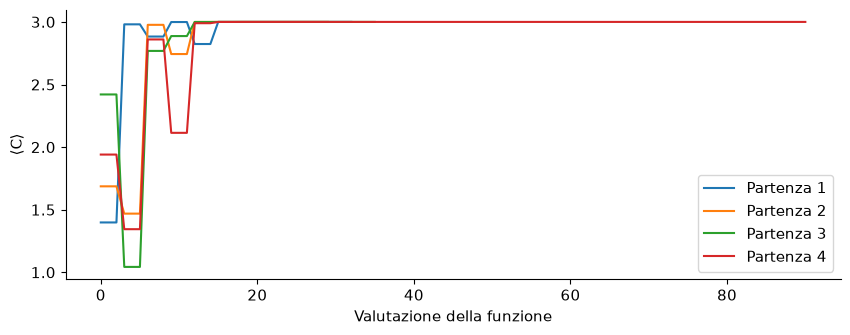

In [15]:
depth=1  # estensione facoltativa: provare 2 strati
result,histories=optimize_qaoa(p=depth,seed=7)
print('Angoli β:',result.x[:depth],'angoli γ:',result.x[depth:])
print('Miglior valore trovato:',-result.fun)
if depth==1:
    assert np.isclose(-result.fun,3,atol=1e-6)
assert -result.fun<=c.max()+1e-9
for j,h in enumerate(histories):plt.plot(h,label=f'Partenza {j+1}')
plt.xlabel('Valutazione della funzione');plt.ylabel('⟨C⟩');plt.legend();plt.show()
# Per due strati gli angoli sono ordinati come [β1,β2,γ1,γ2].

## 3. Dall'ottimizzazione a SAT

Dopo il calcolo QAOA la scansione alla lavagna prevede cinque minuti di pausa. Riprendiamo cambiando la domanda: invece di cercare direttamente il massimo di $C$, fissiamo una soglia $K$ e chiediamo se esiste un assegnamento che la raggiunge.

$$f_K(x)=\mathbf1[C(x)\geq K],\qquad\exists x:\ f_K(x)=1.$$

SAT chiede se una formula booleana è soddisfacibile. Una riduzione corretta deve quindi costruire una formula $\Phi_{G,K}(x,a)$ tale che $\exists a\,\Phi_{G,K}(x,a)$ sia equivalente a $C_G(x)\geq K$ per ogni $x$. Le variabili $a$ sono eventuali ausiliarie. La risposta a una soglia arbitraria non restituisce automaticamente il taglio massimo; per un grafo non pesato si può cercare il valore ottimo con più interrogazioni decisionali, usando la monotonia nella soglia.

Nel quadrato scegliamo $K=4$, il limite superiore dato dal numero di archi. Tutti gli archi devono essere tagliati. Per ciascun arco:
$$x_i\oplus x_j=1\iff(x_i\lor x_j)\land(\neg x_i\lor\neg x_j).$$

La prima clausola esclude 00, la seconda esclude 11. La congiunzione delle otto clausole è in forma normale congiuntiva (CNF); poiché ogni clausola ha due letterali, si tratta di 2-SAT. Questo caso verifica semplicemente che il grafo sia bipartito.

**Esercizio D.** Scrivere le otto clausole. Aggiungere poi la diagonale (1,3): è ancora possibile tagliare ogni arco? Qual è invece il valore di MaxCut?

In [16]:
def all_edges_cnf(edges=SQUARE):
    """CNF 2-SAT che impone di tagliare tutti gli archi (soglia K=m)."""
    return [clause for i, j in edges for clause in ((i+1, j+1), (-i-1, -j-1))]

def satisfies(bits, clauses):
    return all(any(bool(bits[abs(lit)-1]) == (lit > 0) for lit in clause) for clause in clauses)

def threshold_cnf(edges=SQUARE, threshold=4, n=4):
    """Impone y_e <-> x_i XOR x_j e sum(y_e)>=K.

    La cardinalità usa sottoinsiemi: una codifica leggibile per grafi piccoli,
    ma potenzialmente esponenziale. L'appendice A presenta un contatore
    sequenziale di dimensione polinomiale.
    """
    clauses = []
    m = len(edges)
    for k, (i, j) in enumerate(edges):
        a, b, y = i+1, j+1, n+k+1
        clauses += [(a, b, -y), (-a, -b, -y), (a, -b, y), (-a, b, y)]
    if threshold > m:
        clauses.append(())  # Una clausola vuota è sempre falsa.
    elif threshold > 0:
        clauses += list(combinations(range(n+1, n+m+1), m-threshold+1))
    return clauses, n+m

def dimacs(clauses, nvars):
    return f"p cnf {nvars} {len(clauses)}\n" + "\n".join(" ".join(map(str, c)) + " 0" for c in clauses) + "\n"

In [17]:
clauses=all_edges_cnf()
print('CNF in formato DIMACS (segno meno = negazione):')
print(dimacs(clauses,4))
solutions=[name for name,x in zip(labels(),assignments()) if satisfies(x,clauses)]
print('Soluzioni:',solutions)
assert solutions==['0101','1010']
for k in (5,4):
    print('Quadrato + diagonale, K=',k,':',np.array(labels())[costs(DIAGONAL)>=k])

CNF in formato DIMACS (segno meno = negazione):
p cnf 4 8
1 2 0
-1 -2 0
2 3 0
-2 -3 0
3 4 0
-3 -4 0
4 1 0
-4 -1 0

Soluzioni: ['0101', '1010']
Quadrato + diagonale, K= 5 : []
Quadrato + diagonale, K= 4 : ['0101' '1010']


### La soglia generale richiede una cardinalità

Per K diverso da |E| si introducono $y_e\leftrightarrow(x_i\oplus x_j)$ e il vincolo $\sum_e y_e\geq K$. La funzione `threshold_cnf` realizza questa codifica per grafi piccoli con una clausola per ogni sottoinsieme di m−K+1 archi. La dimensione può crescere combinatorialmente: per istanze grandi servono codifiche scalabili, per esempio contatori sequenziali.

I bit y sono determinati da x e saranno calcolati in registri di lavoro, inizializzati a zero e ripuliti. Non prepariamo una sovrapposizione indipendente su queste variabili: Grover cercherà sui soli bit x. La semplice formula 2-SAT con tutti gli archi è solo il caso speciale K=|E|. L'appendice A della dispensa svolge una riduzione polinomiale mediante un contatore; la codifica diretta qui utilizzata serve a mantenere leggibile la CNF dei grafi a quattro vertici.

Come ulteriore collegamento, se invece di soddisfare tutte le clausole della formula a due clausole per arco ne massimizziamo il numero, otteniamo Max-2-SAT. Un arco contribuisce con due clausole vere se è tagliato e una se non lo è, quindi il totale è $m+C(x)$. È un problema di ottimizzazione distinto da 2-SAT.

In [18]:
edges=DIAGONAL; k=4
cnf,nvars=threshold_cnf(edges,k)
for x,value in zip(assignments(),costs(edges)):
    y=[x[i]^x[j] for i,j in edges]
    assert satisfies(list(x)+y,cnf)==(value>=k)
print(f'Verificata la CNF: {nvars} variabili, {len(cnf)} clausole.')

Verificata la CNF: 9 variabili, 30 clausole.


## 4. Dal calcolo booleano all'oracolo

Un oracolo calcola se un candidato soddisfa il predicato; non deve conoscere in anticipo l'elenco delle soluzioni. Una funzione booleana generalmente non è invertibile, perciò conserviamo l'input e scriviamo il risultato in un bersaglio: $|x\rangle|q\rangle\mapsto|x\rangle|q\oplus f_K(x)\rangle$. Questa mappa è una permutazione della base e può essere implementata reversibilmente.

Per il caso centrale C₄, K=4 usiamo la congiunzione delle quattro condizioni XOR, equivalente alla CNF. Non è necessario compilare letteralmente ogni clausola se disponiamo di un'espressione equivalente più semplice.

1. Quattro ancille e memorizzano gli XOR degli archi (due CNOT per arco).
2. Due ancille t memorizzano gli AND intermedi (Toffoli).
3. Un'ancilla q memorizza l'AND finale.
4. Z su q introduce la fase, poi si inverte tutto il calcolo.

$$|x\rangle|0^7\rangle\mapsto(-1)^{f(x)}|x\rangle|0^7\rangle.$$

La rete impiega 4 qubit dati e 7 ancille, con 16 CNOT, 6 Toffoli e una Z, contando anche l'inversione del calcolo. È una costruzione trasparente, non minima; le porte Toffoli richiederebbero una decomposizione su un dispositivo reale.

**Esercizio E.** Seguire gli input 0011 e 0101. Se nelle ancille rimane informazione sull'input, che cosa accade all'interferenza sui dati? Spiegare perché l'uncompute ripristina le ancille senza cancellare la fase. Il solo oracolo modifica le probabilità in base computazionale?

In [19]:
def square_oracle():
    """11 qubit: 4 dati, 4 archi, 2 AND intermedi e 1 risultato.

    Le ancille partono da zero. Il predicato è calcolato dagli archi,
    senza inserire esplicitamente gli assegnamenti soddisfacenti.
    """
    from qiskit import QuantumCircuit, QuantumRegister
    x = QuantumRegister(4, "x")
    e = QuantumRegister(4, "e")
    t = QuantumRegister(2, "t")
    q = QuantumRegister(1, "q")
    comp = QuantumCircuit(x, e, t, q)
    for k, (i, j) in enumerate(SQUARE):
        comp.cx(x[3-i], e[k])
        comp.cx(x[3-j], e[k])
    comp.ccx(e[0], e[1], t[0])
    comp.ccx(e[2], e[3], t[1])
    comp.ccx(t[0], t[1], q[0])
    oracle = comp.copy()
    oracle.z(q[0])
    oracle.compose(comp.inverse(), inplace=True)
    return oracle

In [20]:
oracle=square_oracle()
print(oracle.draw(output='text',fold=100))
initial=np.zeros(2**11,dtype=complex)
initial[:16]=uniform()  # i 7 bit più significativi sono le ancille, tutte zero
after_oracle=Statevector(initial).evolve(oracle).data
assert np.allclose(after_oracle[16:],0)  # ancille ripulite
assert np.allclose(after_oracle[:16],uniform()*np.where(c==4,-1,1))
print('Probabilità ancille non zero:',np.sum(np.abs(after_oracle[16:])**2))
print('Ampiezze dati:',after_oracle[:16].real)

                                                                                               »
x_0: ────────────────────────────────■────■────────────────────────────────────────────■────■──»
                                     │    │                                            │    │  »
x_1: ─────────────────■────■─────────┼────┼────────────────────────────────────────────┼────┼──»
                      │    │         │    │                                            │    │  »
x_2: ───────■────■────┼────┼─────────┼────┼────────────────────────────────────────────┼────┼──»
            │    │    │    │         │    │                                            │    │  »
x_3: ──■────┼────┼────┼────┼─────────┼────┼────■──────────────────────────────────■────┼────┼──»
     ┌─┴─┐┌─┴─┐  │    │    │         │    │    │                                  │    │    │  »
e_0: ┤ X ├┤ X ├──┼────┼────┼────■────┼────┼────┼─────────────────────────────■────┼────┼────┼──»
     └───┘└───┘┌─┴─┐┌─┴─┐  │  

Probabilità ancille non zero: 0.0
Ampiezze dati: [ 0.25  0.25  0.25  0.25  0.25 -0.25  0.25  0.25  0.25  0.25 -0.25  0.25
  0.25  0.25  0.25  0.25]


## 5. SAT con Grover

$$O_f|x\rangle=(-1)^{f(x)}|x\rangle,\quad D=2|s\rangle\langle s|-I,\quad G=DO_f.$$

Assumiamo già noto Grover e applichiamolo al predicato appena costruito. Ci sono $M=2$ stati marcati su $N=16$, quindi $\sin^2\theta=M/N=1/8$ e
$$P_{\rm succ}(r)=\sin^2((2r+1)\theta).$$
Due iterazioni danno probabilità $121/128$. La verifica classica di una stringa accettata è semplicemente $C(x)=4$. La scelta del numero di iterazioni usa qui il valore noto di $M$; una singola misura fallita non certifica UNSAT.

**Esercizio F.** Come breve controllo, usare l'inversione rispetto alla media per ricavare le ampiezze dopo la prima iterazione. Poi confrontare le probabilità per r=0,1,2,3.

In [21]:
def grover_trace(marked, iterations):
    state = uniform(int(np.log2(len(marked))))
    trace = [("Iniziale", state.copy())]
    for r in range(1, iterations + 1):
        state = state * np.where(marked, -1, 1)
        trace.append((f"Oracolo {r}", state.copy()))
        state = 2 * np.mean(state) - state
        trace.append((f"Diffusione {r}", state.copy()))
    return trace

def grover_probability(marked_count, size, iterations):
    theta = np.arcsin(np.sqrt(marked_count / size))
    return float(np.sin((2 * iterations + 1) * theta)**2)

r=0: ampiezza marcata= 0.250000, non marcata= 0.250000, P(successo)=0.12500000
r=1: ampiezza marcata= 0.625000, non marcata= 0.125000, P(successo)=0.78125000
r=2: ampiezza marcata= 0.687500, non marcata=-0.062500, P(successo)=0.94531250
r=3: ampiezza marcata= 0.406250, non marcata=-0.218750, P(successo)=0.33007812


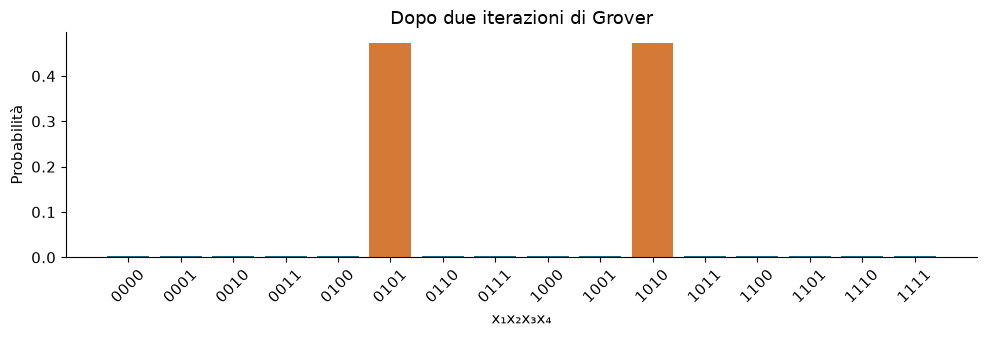

In [22]:
marked=(c==4)
trace=grover_trace(marked,3)
for r,expected in enumerate([1/8,25/32,121/128,169/512]):
    psi=trace[2*r][1]
    print(f'r={r}: ampiezza marcata={psi[5].real: .6f}, '
          f'non marcata={psi[0].real: .6f}, P(successo)={expected:.8f}')
    assert np.isclose(grover_probability(2,16,r),expected)
plot_probabilities(trace[4][1],'Dopo due iterazioni di Grover')

Le probabilità sono $1/8$, $25/32$, $121/128$, $169/512$: la terza iterazione supera il primo picco. La stima asintotica in $\sqrt{N/M}$ riguarda le chiamate all'oracolo; il costo in porte dipende anche dalla sua implementazione. Per il seguito ci servono soprattutto la riflessione $O_f$ e la diffusione $D$.

## 6. Grover come caso particolare di operatori alternati

Per un proiettore P, $e^{-i\alpha P}=I+(e^{-i\alpha}-1)P$.

Poniamo $P_f=\sum_{x:f_K(x)=1}|x\rangle\langle x|$ e $P_s=|s\rangle\langle s|$. Il primo è il costo binario del predicato; il secondo è un nuovo mixer, diverso da $\sum_iX_i$. Per il quadrato con K=4 si può anche scrivere $P_f=H_C(H_C-2I)/8$, perché il polinomio vale 0 sui costi 0 e 2, e 1 sul costo 4. Otteniamo
$$e^{-i\pi P_f}=O_f,\qquad e^{-i\pi P_s}=-D,$$
e dunque
$$\left(e^{-i\pi P_s}e^{-i\pi P_f}\right)^p=(-1)^pG^p.$$

**Esercizio G.** Derivare l'esponenziale usando $P^2=P$ e verificare l'identità. Perché cambiare soltanto gli angoli del QAOA standard non realizza questa costruzione? La fase globale altera le misure?

In [23]:
s=uniform()
Pf=np.diag(marked.astype(float)); Ps=np.outer(s,s.conj())
HC=np.diag(c)
assert np.allclose(Pf,HC@(HC-2*np.eye(16))/8)
O=np.eye(16)-2*Pf; D=2*Ps-np.eye(16)
layer=expm(-1j*np.pi*Ps)@expm(-1j*np.pi*Pf)
print('Errore tra operatori:',np.linalg.norm(layer+D@O))
assert np.allclose(layer,-D@O)
p=2
generalized=alternating(marked,[np.pi]*p,[np.pi]*p,'projector')
grover=grover_trace(marked,p)[-1][1]
assert np.allclose(generalized,(-1)**p*grover)
standard=alternating(marked,[np.pi]*p,[np.pi]*p,'x')
print('Fedeltà con Grover, mixer a proiettore:',abs(np.vdot(grover,generalized))**2)
print('P(soluzione) con mixer standard:',np.sum(np.abs(standard[marked])**2))

Errore tra operatori: 1.558087866629125e-15
Fedeltà con Grover, mixer a proiettore: 1.0
P(soluzione) con mixer standard: 0.125


La dimostrazione riguarda il **proiettore del predicato e il mixer sullo stato uniforme**, con angoli π. In questa famiglia generalizzata di operatori alternati, ogni strato coincide con un iterato di Grover a meno di fase globale. L'identità vale fra operatori, non soltanto per lo stato iniziale scelto. Con il mixer standard, invece, $e^{-i\pi\sum_iX_i}=I$ su quattro qubit.

Il confronto 53,125% (QAOA p=1) e 94,53125% (Grover r=2) non è un confronto delle risorse richieste: sono diversi gli operatori, la soglia fornita e il costo dell'oracolo.

## 7. Il significato dei risultati delle misure

In entrambi i casi una misura restituisce una stringa classica. La sequenza di risultati $T=(x^{(1)},\ldots,x^{(S)})$ permette di calcolare quantità diverse, a seconda della funzione associata a ogni stringa:
$$\widehat F=\frac1S\sum_x n_x C_G(x),\qquad
\widehat P_{\rm succ}=\frac1S\sum_x n_x f_{G,K}(x).$$

Nel QAOA variazionale la stima del costo guida la scelta dei nuovi angoli; alla fine si campionano candidati. Nel Grover standard gli angoli delle riflessioni sono fissati e il risultato viene verificato. La natura dei dati di misura è la stessa; cambia il loro ruolo nel protocollo.

La funzione $F_{G,p}$ non viene restituita direttamente dal circuito: un insieme di misure ne stima il valore in un punto dello spazio dei parametri. Anche la famiglia che contiene Grover ha una funzione obiettivo, scegliendo come osservabile il proiettore $P_f$:
$$F_p^{(f,s)}(\vartheta)=\langle\psi_p^{(f,s)}(\vartheta)|P_f|\psi_p^{(f,s)}(\vartheta)\rangle.$$
Al punto con tutti gli angoli uguali a π,
$$F_p^{(f,s)}(\pi\mathbf1,\pi\mathbf1)=P_{\rm succ}(p).$$
Gli angoli sono stati fissati, mentre la dipendenza dall'istanza e dal numero di iterazioni rimane. La legge di successo dipende soltanto da N, M e p grazie alla simmetria di Grover: tutte le stringhe marcate hanno la stessa ampiezza, così come tutte le non marcate. Questa proprietà esiste già prima della misura.

### Due osservabili sugli stessi conteggi

La cella seguente usa il circuito di riferimento QAOA e Grover con due iterazioni. Per ciascuno raccoglie un campione e calcola sia il costo medio sia la frequenza di accettazione. I conteggi riassumono i risultati delle misure, sufficiente per entrambi gli stimatori.

In [24]:
transcript_shots, transcript_seed = 1024, 11
grover_state = grover_trace(c>=4,2)[-1][1]
for method,psi in [('QAOA p=1',reference_state),('Grover r=2',grover_state)]:
    observed = sample(psi,transcript_shots,transcript_seed)
    mean_cost = observed@c/transcript_shots
    acceptance = observed@(c>=4)/transcript_shots
    print(f'{method}: media campionata={mean_cost:.5f}, '
          f'frequenza accettazione={acceptance:.5f}')
    print('  Valori esatti:',expectation(psi,c),expectation(psi,c>=4))
    print('  Conteggi:',dict(zip(labels(),observed.tolist())))
    assert observed.sum()==transcript_shots
for r in range(4):
    psi=grover_trace(c>=4,r)[-1][1]
    success=grover_probability(2,16,r)
    assert np.isclose(expectation(psi,c),12/7+16*success/7)
print('Costo medio esatto dopo due iterazioni di Grover:',31/8)

QAOA p=1: media campionata=3.01367, frequenza accettazione=0.53320
  Valori esatti: 3.0 0.53125
  Conteggi: {'0000': 12, '0001': 16, '0010': 17, '0011': 79, '0100': 22, '0101': 270, '0110': 97, '0111': 14, '1000': 15, '1001': 75, '1010': 276, '1011': 16, '1100': 73, '1101': 14, '1110': 13, '1111': 15}
Grover r=2: media campionata=3.89453, frequenza accettazione=0.95312
  Valori esatti: 3.875 0.9453125
  Conteggi: {'0000': 2, '0001': 4, '0010': 4, '0011': 1, '0100': 2, '0101': 516, '0110': 2, '0111': 7, '1000': 4, '1001': 3, '1010': 460, '1011': 4, '1100': 3, '1101': 2, '1110': 6, '1111': 4}
Costo medio esatto dopo due iterazioni di Grover: 3.875


Nel quadrato la media del costo fra gli stati marcati è 4, mentre fra i non marcati è $12/7$. Perciò anche dopo Grover è definito il costo medio
$$\langle C\rangle_r^{\rm Grover}=\frac{12}{7}+\frac{16}{7}P_{\rm succ}(r).$$
La sua stima usa le stesse stringhe impiegate per verificare il predicato.

### Quale informazione sulla topologia rimane?

Aggiungiamo la diagonale (1,3) e manteniamo K=4. Se $x_1\ne x_3$, ciascun cammino di due lati fra i vertici 1 e 3 contiene un solo arco tagliato: il costo totale, diagonale compresa, è 3. Se $x_1=x_3$, la diagonale non contribuisce. Le uniche stringhe accettate rimangono quindi 0101 e 1010.

I due grafi hanno costi diversi ma lo stesso predicato a questa soglia. Definiscono perciò lo stesso oracolo ideale sui dati e la stessa distribuzione di Grover a ogni r. Il QAOA standard, usando il valore del taglio, distingue invece le due istanze. A parità del solo numero M, Grover avrebbe la stessa probabilità totale di successo, ma non necessariamente la stessa distribuzione sulle stringhe etichettate.

**Esercizio H.** Verificare questo confronto e spiegare perché la topologia non viene cancellata dalla misura. Con lo stesso stato di Grover, i due grafi devono avere anche lo stesso costo medio?

In [25]:
c_diagonal = costs(DIAGONAL)
assert np.array_equal(c>=4,c_diagonal>=4)
assert np.allclose(grover_trace(c>=4,2)[-1][1],
                   grover_trace(c_diagonal>=4,2)[-1][1])
q_diagonal=qaoa([np.pi/8],[np.pi/4],DIAGONAL)
assert not np.allclose(np.abs(reference_state)**2,np.abs(q_diagonal)**2)
print('Distanza fra distribuzioni QAOA:',
      np.linalg.norm(np.abs(reference_state)**2-np.abs(q_diagonal)**2))
print('Stesso stato Grover, costo medio sul quadrato:',expectation(grover_state,c))
print('Stesso stato Grover, costo medio con diagonale:',expectation(grover_state,c_diagonal))

Distanza fra distribuzioni QAOA: 0.15741001584372064
Stesso stato Grover, costo medio sul quadrato: 3.875
Stesso stato Grover, costo medio con diagonale: 3.90625


Il confronto separa tre scelte: come prepariamo lo stato, quale osservabile ricaviamo dalle stringhe e come usiamo la stima. L'identità con Grover riguarda la preparazione in una specifica famiglia; non impone a tutti gli algoritmi lo stesso uso classico delle misure.

## Soluzioni degli esercizi

- **A:** i costi sono 0, 2, 4 con molteplicità 2, 12, 2. 0101 e 1010 descrivono la stessa bipartizione non ordinata, ma sono due stati di base.
- **B:** con β=0 le fasi non si convertono in probabilità. Con γ=0, |+⟩⊗4 è autostato di ΣX. La distribuzione resta uniforme e la media vale 2.
- **C:** il valore intero di una stringa non è il numero di archi tagliati. La media corretta è `counts @ c / shots`. L'errore standard diminuisce come 1/√S; un singolo campione può oscillare.
- **D:** il quadrato dà otto clausole e due soluzioni. La diagonale crea triangoli: K=5 è UNSAT, ma K=4 è SAT e il massimo è 4. Per soglie generiche occorre la cardinalità.
- **E:** per 0011 gli XOR sono 0101 e f=0; per 0101 sono 1111 e f=1. L'uncompute ripulisce le ancille preservando la fase. Le probabilità dopo il solo oracolo sono invariate.
- **F:** la media è 3/16, le ampiezze dopo diffusione sono 5/8 e 1/8. P(soluzione)=25/32. Dopo due iterazioni sono 11/16 e −1/16.
- **G:** Pᵏ=P per k≥1, perciò la serie esponenziale si raccoglie in I+(e⁻ⁱᵅ−1)P. Il mixer |s⟩⟨s| sostituisce ΣX e produce −D all'angolo π.
- **H:** il predicato a K=4 e lo stato di Grover coincidono. Il costo medio può cambiare perché cambia l'osservabile: dopo due iterazioni vale 31/8 sul quadrato e 125/32 con la diagonale. Il numero di iterazioni e l'insieme marcato restano parte della distribuzione; la misura non ne cancella la dipendenza.

## Fonti

Percorso basato sulle note fornite *From MaxCut to SAT, Grover, and Back to QAOA*. Convenzioni aggiornate rispetto al notebook precedente `tutorial_3_2.ipynb`.

- [Farhi, Goldstone, Gutmann: QAOA](https://arxiv.org/abs/1411.4028)
- [Hadfield et al.: operatori alternati](https://arxiv.org/abs/1709.03489)
- [Grover: ricerca quantistica](https://arxiv.org/abs/quant-ph/9605043)
- [Brassard et al.: amplificazione e stima di ampiezza](https://arxiv.org/abs/quant-ph/0005055)
- [IBM: convenzione RZZ](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.RZZGate)